# Setup

## GPU Initialization

In [1]:
import os
os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")            # before torch/numpy
os.environ.setdefault("HF_HUB_DISABLE_SYMLINKS_WARNING", "1")

# Keras 3 runs the CNN / BiLSTM on the PyTorch backend (no TensorFlow).
# MUST be set before `import keras` anywhere in the kernel.
os.environ.setdefault("KERAS_BACKEND", "torch")
os.environ.setdefault("USE_TF", "0")                            # stop transformers importing TF

import sys, subprocess, importlib.util

# torch: needs the cu130 wheel for the RTX 5070 (Blackwell / sm_120)
try:
    import torch
    assert torch.cuda.is_available() and torch.version.cuda
    print(f"OK: torch {torch.__version__} (CUDA {torch.version.cuda})")
except (ImportError, AssertionError):
    subprocess.check_call([sys.executable, "-m", "pip", "install", "--upgrade",
        "torch", "torchvision", "--index-url", "https://download.pytorch.org/whl/cu130"])
    raise SystemExit(">>> Installed torch — RESTART KERNEL, then re-run from top <<<")

# accelerate: required by HF Trainer. Install only if missing, never -U.
if importlib.util.find_spec("accelerate") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "accelerate>=1.1.0"])
    raise SystemExit(">>> Installed accelerate — RESTART KERNEL <<<")

# keras 3: pure-Python, uses the torch already installed. No TensorFlow.
if importlib.util.find_spec("keras") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "keras>=3.5"])
    raise SystemExit(">>> Installed keras — RESTART KERNEL <<<")

OK: torch 2.13.0+cu130 (CUDA 13.0)


In [2]:
import gc, torch

torch.backends.cuda.matmul.allow_tf32 = True
torch.backends.cudnn.allow_tf32 = True

assert torch.cuda.is_available(), "CUDA not available — check Cell 1, restart kernel."
device = torch.device("cuda")

p = torch.cuda.get_device_properties(0)
print(f"{torch.__version__} | {p.name} | {p.total_memory/1e9:.1f} GB "
      f"| cap {p.major}.{p.minor} | bf16={torch.cuda.is_bf16_supported()}")

def free_gpu():
    """del the trainer/model in the notebook first, then call this."""
    gc.collect(); torch.cuda.empty_cache(); torch.cuda.reset_peak_memory_stats()
    print(f"GPU allocated: {torch.cuda.memory_allocated()/1e9:.2f} GB")

2.13.0+cu130 | NVIDIA GeForce RTX 5070 Laptop GPU | 8.5 GB | cap 12.0 | bf16=True


In [3]:
import keras

print("PyTorch:", torch.__version__)
print("Keras:", keras.__version__, "| backend:", keras.config.backend())
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

# Keras uses the same CUDA device as torch. Quick proof it lands on the GPU:
_probe = keras.layers.Dense(1)
_probe.build((None, 4))
print("Keras variable device:", _probe.weights[0].value.device)

PyTorch: 2.13.0+cu130
Keras: 3.15.1 | backend: torch
CUDA available: True
GPU: NVIDIA GeForce RTX 5070 Laptop GPU
Keras variable device: cuda:0


## Imports

In [4]:
import os
import gc
import json
import random
import re
import pickle
import joblib
import copy
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

import torch

from sklearn.model_selection import (
    train_test_split,
    GroupShuffleSplit
)

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

from scipy.sparse import hstack

from datasets import Dataset

from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    DataCollatorWithPadding,
    TrainingArguments,
    Trainer
)

# --- Keras 3 on the PyTorch backend (KERAS_BACKEND set in the GPU-init cell) ---
import keras
from keras import Sequential
from keras.layers import (
    Embedding,
    Conv1D,
    GlobalMaxPooling1D,
    Bidirectional,
    LSTM,
    Dense,
    Dropout
)

assert keras.config.backend() == "torch", (
    f"Keras backend is {keras.config.backend()!r}, expected 'torch'. "
    "Set os.environ['KERAS_BACKEND']='torch' before importing keras and restart the kernel."
)

## Paths & Variables

In [5]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
keras.utils.set_random_seed(SEED)   # seeds python / numpy / torch for the keras backend

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# ============================================================
# PATHS
# ============================================================

OUTPUT_PATH = "models"   # relative to the notebook; "/models" would write to the drive root

os.makedirs(OUTPUT_PATH, exist_ok=True)

# ============================================================
# MODEL OUTPUT LAYOUT
# models/<category>/{logreg.joblib, textcnn/, bilstm/, distilbert/}
# ============================================================

CATEGORY_NAME = "toxic"

CATEGORY_DIR = f"{OUTPUT_PATH}/{CATEGORY_NAME}"
TEXTCNN_DIR = f"{CATEGORY_DIR}/textcnn"
BILSTM_DIR = f"{CATEGORY_DIR}/bilstm"
DISTILBERT_DIR = f"{CATEGORY_DIR}/distilbert"

for _dir in (CATEGORY_DIR, TEXTCNN_DIR, BILSTM_DIR, DISTILBERT_DIR):
    os.makedirs(_dir, exist_ok=True)

LABELS = ["not_toxic", "toxic"]

with open(f"{CATEGORY_DIR}/labels.json", "w") as f:
    json.dump(LABELS, f, indent=2)

# ============================================================
# TRAINING FILES
# ============================================================

TOXIC_TRAIN_PATH = "train/toxic_train.csv"
SGHATE_TRAIN_PATH = "train/ss_annotations.csv"

# ============================================================
# FINAL TEST FILES
# DO NOT USE DURING MODEL DEVELOPMENT
# ============================================================

TOXIC_TEST_PATH = "test/toxic_test.csv"
TOXIC_TEST_LABELS_PATH = "test/toxic_test_labels.csv" 
SGHATE_TEST_PATH = "test/ss_testcases_all.csv"

# ============================================================
# TRANSFORMER SETTINGS
# ============================================================

DISTILBERT_NAME = "distilbert-base-uncased"

MAX_LENGTH = 128

TRAIN_BATCH_SIZE = 16
EVAL_BATCH_SIZE = 32

NUM_EPOCHS = 3
LEARNING_RATE = 2e-5

# ============================================================
# NEURAL NETWORK SETTINGS
# ============================================================

VOCAB_SIZE = 30000
SEQUENCE_LENGTH = 128
EMBEDDING_DIM = 128

# ============================================================
# DATASET EXPERIMENT SETTINGS
# ============================================================

TOXIC_TARGET_SIZE = 50000

# ============================================================
# BAGGING
# Start small first.
#
# Later compare:
# 1, 3, 5, 10, 15
# ============================================================

N_BAGS = 3

# Data Preprocessing

## Load Datasets

In [6]:
toxic_raw = pd.read_csv(TOXIC_TRAIN_PATH)
sghate_raw = pd.read_csv(SGHATE_TRAIN_PATH)
toxic_test_raw = pd.read_csv(TOXIC_TEST_PATH)
toxic_test_labels_raw = pd.read_csv(TOXIC_TEST_LABELS_PATH)
sghate_test_raw = pd.read_csv(SGHATE_TEST_PATH)

print("Toxic Train:", toxic_raw.shape)
print("SGHateCheck Train:", sghate_raw.shape)
print("Toxic Test:", toxic_test_raw.shape)
print("Toxic Test Labels:", toxic_test_labels_raw.shape)
print("SGHateCheck Test:", sghate_test_raw.shape)

Toxic Train: (159571, 8)
SGHateCheck Train: (2974, 20)
Toxic Test: (153164, 2)
Toxic Test Labels: (153164, 7)
SGHateCheck Test: (7023, 10)


## Visualize Data

In [7]:
print("TOXIC TRAIN")
display(toxic_raw.head())

print("SGHateCheck TRAIN")
display(sghate_raw.head())

print("TOXIC TEST")
display(toxic_test_raw.head())

print("SGHateCheck TEST")
display(sghate_test_raw.head())

TOXIC TRAIN


,id,comment_text,toxic,severe_toxic,obscene,threat,insult,identity_hate
0,0000997932d777bf,Explanation\nWhy the edits made under my usern...,0,0,0,0,0,0
1,000103f0d9cfb60f,D'aww! He matches this background colour I'm s...,0,0,0,0,0,0
2,000113f07ec002fd,"Hey man, I'm really not trying to edit war. It...",0,0,0,0,0,0
3,0001b41b1c6bb37e,"""\nMore\nI can't make any real suggestions on ...",0,0,0,0,0,0
4,0001d958c54c6e35,"You, sir, are my hero. Any chance you remember...",0,0,0,0,0,0


SGHateCheck TRAIN


,Unnamed: 0.2,Unnamed: 0.1,c_id,annotator_2,annotator_3,index,Unnamed: 0,p_label,p_value,p_target,c_testcase,t_case_local,t_function,t_gold,t_direction,t_id,c_order,annotator_1,annotation_common,annotation_selected
0,0,0,0,hateful,hateful,0,0,{IDENTITY_P},chinese,Chinese,Fuck all chinese lah.,Fuck all {IDENTITY_P} lah.,profanity_h,hateful,general,243,788,hateful,hateful,hateful
1,1,1,1,hateful,hateful,1,1,{IDENTITY_P},malays,Malay,Fuck all malays lah.,Fuck all {IDENTITY_P} lah.,profanity_h,hateful,general,243,1013,hateful,hateful,hateful
2,2,2,2,hateful,hateful,2,2,{IDENTITY_P},indians,Indians,Fuck all indians lah.,Fuck all {IDENTITY_P} lah.,profanity_h,hateful,general,243,2722,hateful,hateful,hateful
3,3,3,3,hateful,hateful,3,3,{IDENTITY_P},christians,Christian,Fuck all christians lah.,Fuck all {IDENTITY_P} lah.,profanity_h,hateful,general,243,2917,hateful,hateful,hateful
4,4,4,4,hateful,hateful,4,4,{IDENTITY_P},muslims,Muslim,Fuck all muslims lah.,Fuck all {IDENTITY_P} lah.,profanity_h,hateful,general,243,2591,hateful,hateful,hateful


TOXIC TEST


,id,comment_text
0,00001cee341fdb12,Yo bitch Ja Rule is more succesful then you'll...
1,0000247867823ef7,== From RfC == \n\n The title is fine as it is...
2,00013b17ad220c46,""" \n\n == Sources == \n\n * Zawe Ashton on Lap..."
3,00017563c3f7919a,":If you have a look back at the source, the in..."
4,00017695ad8997eb,I don't anonymously edit articles at all.


SGHateCheck TEST


,Unnamed: 0,p_label,p_value,p_target,c_testcase,t_case_local,t_function,t_gold,t_direction,t_id
0,0,{IDENTITY_P},chinese,Chinese,Execution is the only solution for those chine...,Execution is the only solution for those {IDEN...,threat_dir_h,hateful,directed,97
1,1,{IDENTITY_P},malays,Malay,Execution is the only solution for those malay...,Execution is the only solution for those {IDEN...,threat_dir_h,hateful,directed,97
2,2,{IDENTITY_P},indians,Indians,Execution is the only solution for those india...,Execution is the only solution for those {IDEN...,threat_dir_h,hateful,directed,97
3,3,{IDENTITY_P},christians,Christian,Execution is the only solution for those chris...,Execution is the only solution for those {IDEN...,threat_dir_h,hateful,directed,97
4,4,{IDENTITY_P},muslims,Muslim,Execution is the only solution for those musli...,Execution is the only solution for those {IDEN...,threat_dir_h,hateful,directed,97


## Prepare Toxic Train Dataset

In [8]:
def clean_text_dataframe(df):
    df = df.copy()

    df["text"] = (
        df["text"]
        .fillna("")
        .astype(str)
        .str.strip()
    )

    df = df[df["text"] != ""]

    df = df.drop_duplicates(subset=["text"])

    return df.reset_index(drop=True)

In [9]:
TOXIC_COLUMNS = ["toxic", "severe_toxic", "obscene", "threat", "insult", "identity_hate"]

def prepare_jigsaw_toxic(df):

    df = df.copy()

    df["text"] = (
        df["comment_text"]
        .fillna("")
        .astype(str)
    )

    df["label"] = (
        df[TOXIC_COLUMNS]
        .max(axis=1)
        .astype(int)
    )

    df["source"] = "jigsaw"

    return clean_text_dataframe(
        df[["text", "label", "source"]]
    )


jigsaw_toxic = prepare_jigsaw_toxic(toxic_raw)

print(jigsaw_toxic.shape)
print(jigsaw_toxic["label"].value_counts())
print(jigsaw_toxic["label"].value_counts(normalize=True))

(159571, 3)
label
0    143346
1     16225
Name: count, dtype: int64
label
0    0.898321
1    0.101679
Name: proportion, dtype: float64


In [10]:
def create_toxic_subset(df, target_size=50000, seed=42):

    positive = df[df["label"] == 1]
    negative = df[df["label"] == 0]

    n_positive = len(positive)
    n_negative = min(target_size-n_positive, len(negative))

    sampled_negative = negative.sample(n=n_negative, random_state=seed)

    result = pd.concat([positive, sampled_negative], ignore_index=True)

    return (
        result
        .sample(frac=1, random_state=seed)
        .reset_index(drop=True)
    )

jigsaw_subset = create_toxic_subset(jigsaw_toxic, TOXIC_TARGET_SIZE, SEED)

print(jigsaw_subset.shape)
print(jigsaw_subset["label"].value_counts())

(50000, 3)
label
0    33775
1    16225
Name: count, dtype: int64


### Train Test Split Toxic

In [11]:
jigsaw_train, jigsaw_val = train_test_split(
    jigsaw_subset,
    test_size=0.15,
    random_state=SEED,
    stratify=jigsaw_subset["label"]
)

print("Jigsaw train:", jigsaw_train.shape)
print("Jigsaw validation:", jigsaw_val.shape)
display(jigsaw_train.head())

Jigsaw train: (42500, 3)
Jigsaw validation: (7500, 3)


,text,label,source
15606,Could idiotic self-righteous people please ref...,1,jigsaw
20721,Thanks for the pointer. Clarification seems t...,0,jigsaw
38566,"""\n\nNatalie said: """"If Wikipedia had existed ...",0,jigsaw
27147,So if your doing a correspondance in R^2 how w...,0,jigsaw
13420,You fascit Nazi! You socialist bastard! You fi...,1,jigsaw


## Prepare SGHateCheck

In [12]:
def prepare_sghate(df):

    df = df.copy()

    df = df[
        df["t_gold"].isin(["hateful", "non-hateful"])
    ]

    df["text"] = (
        df["c_testcase"]
        .fillna("")
        .astype(str)
    )

    df["label"] = (
        df["t_gold"]
        .map({"hateful": 1, "non-hateful": 0})
        .astype(int)
    )

    df["source"] = "sghatecheck"

    columns = ["text", "label", "source", "t_case_local", "t_function", "t_direction", "t_id"]

    return df[columns].reset_index(drop=True)


sghate = prepare_sghate(sghate_raw)

print(sghate.shape)
print(sghate["label"].value_counts())

(2974, 7)
label
1    2314
0     660
Name: count, dtype: int64


### Split SGHateCheck by template

In [13]:
group_split = GroupShuffleSplit(
    n_splits=1,
    test_size=0.15,
    random_state=SEED
)

train_idx, val_idx = next(
    group_split.split(
        sghate,
        y=sghate["label"],
        groups=sghate["t_case_local"]
    )
)

sghate_train = (
    sghate
    .iloc[train_idx]
    .reset_index(drop=True)
)

sghate_val = (
    sghate
    .iloc[val_idx]
    .reset_index(drop=True)
)

train_templates = set(sghate_train["t_case_local"])

val_templates = set(sghate_val["t_case_local"])

overlap = train_templates.intersection(val_templates)

print("SG train:", sghate_train.shape)
print("SG validation:", sghate_val.shape)
print("Template overlap:", len(overlap))

assert len(overlap) == 0

SG train: (2551, 7)
SG validation: (423, 7)
Template overlap: 0


## Combine SGHate-Toxic Training Set

In [14]:
toxic_train_sg = pd.concat(
    [
        jigsaw_train[["text", "label", "source"]],
        sghate_train[["text", "label", "source"]]
    ],
    ignore_index=True
)

toxic_train_sg = (
    toxic_train_sg
    .sample(frac=1, random_state=SEED)
    .reset_index(drop=True)
)

print(toxic_train_sg.shape)
print(toxic_train_sg["source"].value_counts())
print(toxic_train_sg["label"].value_counts())
display(toxic_train_sg.head())

(45051, 3)
source
jigsaw         42500
sghatecheck     2551
Name: count, dtype: int64
label
0    29255
1    15796
Name: count, dtype: int64


,text,label,source
0,When you can't come up with a genuine reason t...,1,jigsaw
1,"""\n\nIn the mean time, I guess I've a got a so...",1,jigsaw
2,Sorry: I went to the right page and provided a...,0,jigsaw
3,|class = | importance= |,0,jigsaw
4,"""\n\n Definition of German cultural background...",0,jigsaw


## Prepare Toxic Test Set

In [15]:
toxic_test_merged = toxic_test_raw.merge(toxic_test_labels_raw, on="id", how="left", validate="one_to_one")
assert len(toxic_test_merged) == len(toxic_test_raw)

toxic_test_scored = toxic_test_merged[(toxic_test_merged[TOXIC_COLUMNS] >= 0).all(axis=1)]
toxic_test = prepare_jigsaw_toxic(toxic_test_scored)

print("Test rows with labels:", len(toxic_test_scored), "of", len(toxic_test_raw))
print(toxic_test.shape)
print(toxic_test["label"].value_counts())
print(toxic_test["label"].value_counts(normalize=True)) 
display(toxic_test.head())

Test rows with labels: 63978 of 153164
(63977, 3)
label
0    57734
1     6243
Name: count, dtype: int64
label
0    0.902418
1    0.097582
Name: proportion, dtype: float64


,text,label,source
0,Thank you for understanding. I think very high...,0,jigsaw
1,:Dear god this site is horrible.,0,jigsaw
2,"""::: Somebody will invariably try to add Relig...",0,jigsaw
3,""" \n\n It says it right there that it IS a typ...",0,jigsaw
4,""" \n\n == Before adding a new product to the l...",0,jigsaw


## Prepare SGHateCheck Test Set

`ss_testcases_all.csv` is a superset of the SG train annotations, so every row built from a template used in `sghate_train` is dropped (the model has already trained on those templates). The remaining rows are formatted with `prepare_sghate`, de-duplicated, and stacked under `toxic_test` as `toxic_test_combined`. The `source` column (`jigsaw` / `sghatecheck`) lets you report each part separately.

In [16]:
sghate_test_all = prepare_sghate(sghate_test_raw) 
# Drops rows that the model is already trained on
sghate_test = sghate_test_all[~sghate_test_all["t_case_local"].isin(sghate_train["t_case_local"])]
sghate_test = clean_text_dataframe(sghate_test)

display(sghate_test.head())

,text,label,source,t_case_local,t_function,t_direction,t_id
0,Execution is the only solution for those chine...,1,sghatecheck,Execution is the only solution for those {IDEN...,threat_dir_h,directed,97
1,Execution is the only solution for those malay...,1,sghatecheck,Execution is the only solution for those {IDEN...,threat_dir_h,directed,97
2,Execution is the only solution for those india...,1,sghatecheck,Execution is the only solution for those {IDEN...,threat_dir_h,directed,97
3,Execution is the only solution for those chris...,1,sghatecheck,Execution is the only solution for those {IDEN...,threat_dir_h,directed,97
4,Execution is the only solution for those musli...,1,sghatecheck,Execution is the only solution for those {IDEN...,threat_dir_h,directed,97


## Combine SGHate-Toxic Test Set

In [17]:
toxic_test_combined = pd.concat(
    [
        toxic_test[["text", "label", "source"]], 
        sghate_test[["text", "label", "source"]]
    ],
    ignore_index=True 
)

print("SGHateCheck test rows:", len(sghate_test_all), "-> kept:", len(sghate_test))  
print(toxic_test_combined.shape)
print(toxic_test_combined["source"].value_counts())
print(toxic_test_combined["label"].value_counts()) 
display(toxic_test_combined.head())

SGHateCheck test rows: 7023 -> kept: 4340
(68317, 3)
source
jigsaw         63977
sghatecheck     4340
Name: count, dtype: int64
label
0    59236
1     9081
Name: count, dtype: int64


,text,label,source
0,Thank you for understanding. I think very high...,0,jigsaw
1,:Dear god this site is horrible.,0,jigsaw
2,"""::: Somebody will invariably try to add Relig...",0,jigsaw
3,""" \n\n It says it right there that it IS a typ...",0,jigsaw
4,""" \n\n == Before adding a new product to the l...",0,jigsaw


# Base Model Support Functions

## Binary Evaluation Function

In [18]:
def evaluate_binary(y_true, probabilities, threshold=0.5, model_name=""):

    probabilities = np.asarray(probabilities)
    predictions = (probabilities >= threshold).astype(int)

    result = {
        "model": model_name,
        "accuracy": accuracy_score(y_true, predictions),
        "precision": precision_score(y_true, predictions, zero_division=0),
        "recall": recall_score(y_true, predictions, zero_division=0),
        "f1": f1_score(y_true, predictions, zero_division=0)
    }

    try:
        result["roc_auc"] = roc_auc_score(y_true, probabilities)
    except ValueError:
        result["roc_auc"] = np.nan

    print("\n", "=" * 60)
    print(model_name)
    print("=" * 60)
    print(result)
    print(classification_report(y_true, predictions, zero_division=0))
    print("Confusion matrix:\n", confusion_matrix(y_true, predictions))

    return result

## Text Vectorizer for Keras models

In [19]:
from inference import KerasTextVectorizer

print("KerasTextVectorizer ready (imported from inference.py).")

KerasTextVectorizer ready (imported from inference.py).


## Base Model Prediction Functions

In [20]:
def predict_lr(model_bundle, texts):

    word = (model_bundle["word_vectorizer"].transform(texts))
    char = (model_bundle["char_vectorizer"].transform(texts))

    X = hstack([word, char])

    return (model_bundle["model"].predict_proba(X)[:, 1])


def predict_neural(model_bundle, texts):

    # vectorize with the SAME adapted vocab used at training time
    X = model_bundle["vectorizer"](np.asarray(texts, dtype=object))

    return (model_bundle["model"].predict(X, batch_size=128, verbose=0).ravel())


def predict_distilbert(trainer_bundle, df):

    dataset = make_hf_dataset(df)
    output = (trainer_bundle["trainer"].predict(dataset))
    logits = output.predictions
    probabilities = torch.softmax(torch.tensor(logits), dim=-1).numpy()

    return probabilities[:, 1]

# Base Model Training Functions

## Model 1 - TF-IDF + Logistic Regression

In [21]:
def train_logistic_model(train_df, val_df, model_name, output_name):

    # ========================================================
    # WORD TF-IDF
    # ========================================================

    word_vectorizer = TfidfVectorizer(
        analyzer="word",
        ngram_range=(1, 2),
        min_df=2,
        max_features=50000,
        sublinear_tf=True
    )

    # ========================================================
    # CHARACTER TF-IDF
    # ========================================================

    char_vectorizer = TfidfVectorizer(
        analyzer="char_wb",
        ngram_range=(3, 5),
        min_df=2,
        max_features=50000,
        sublinear_tf=True
    )

    X_train_word = (word_vectorizer.fit_transform(train_df["text"]))
    X_val_word = (word_vectorizer.transform(val_df["text"]))

    X_train_char = (char_vectorizer.fit_transform(train_df["text"]))
    X_val_char = (char_vectorizer.transform(val_df["text"]))

    X_train = hstack([X_train_word, X_train_char])
    X_val = hstack([X_val_word, X_val_char])

    y_train = train_df["label"].values
    y_val = val_df["label"].values

    model = LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        solver="liblinear",
        random_state=SEED
    )
    model.fit(X_train, y_train)

    probabilities = (model.predict_proba(X_val)[:, 1])

    results = evaluate_binary(
        y_val,
        probabilities,
        threshold=0.5,
        model_name=model_name
    )

    joblib.dump(
        {
            "model": model,
            "word_vectorizer": word_vectorizer,
            "char_vectorizer": char_vectorizer
        },
        f"{OUTPUT_PATH}/{output_name}.joblib"
    )

    return {
        "model": model,
        "word_vectorizer": word_vectorizer,
        "char_vectorizer": char_vectorizer,
        "probabilities": probabilities,
        "results": results
    }

## Model 2 - TextCNN / CNN-1D

In [22]:
def train_textcnn(train_df, val_df, model_name, output_name, seed=42):

    keras.backend.clear_session()
    keras.utils.set_random_seed(seed)

    # --- vectorize outside the model (NumPy int32 sequences) ---
    vectorizer = KerasTextVectorizer(
        max_tokens=VOCAB_SIZE,
        output_sequence_length=SEQUENCE_LENGTH
    )
    vectorizer.adapt(train_df["text"].values)

    X_train = vectorizer(train_df["text"].values)
    X_val = vectorizer(val_df["text"].values)
    y_train = train_df["label"].values
    y_val = val_df["label"].values

    model = Sequential([
        keras.Input(shape=(SEQUENCE_LENGTH,), dtype="int32"),
        Embedding(input_dim=VOCAB_SIZE, output_dim=EMBEDDING_DIM),
        Conv1D(filters=128, kernel_size=5, activation="relu"),
        GlobalMaxPooling1D(),
        Dense(64, activation="relu"),
        Dropout(0.3),
        Dense(1, activation="sigmoid", dtype="float32")
    ])

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=1e-3),
        loss="binary_crossentropy",
        metrics=[
            "accuracy",
            keras.metrics.Precision(name="precision"),
            keras.metrics.Recall(name="recall"),
            keras.metrics.AUC(name="auc")
        ]
    )

    checkpoint_path = (f"{OUTPUT_PATH}/{output_name}.keras")

    callbacks = [
        keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=2,
            restore_best_weights=True
        ),
        keras.callbacks.ModelCheckpoint(
            checkpoint_path,
            monitor="val_loss",
            save_best_only=True
        )
    ]

    history = model.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=8,
        batch_size=64,
        callbacks=callbacks,
        verbose=1
    )

    probabilities = (model.predict(X_val, batch_size=128, verbose=0).ravel())

    results = evaluate_binary(
        y_val,
        probabilities,
        threshold=0.5,
        model_name=model_name
    )

    joblib.dump(vectorizer, f"{OUTPUT_PATH}/{output_name}_vectorizer.joblib")

    return {
        "model": model,
        "vectorizer": vectorizer,
        "history": history,
        "probabilities": probabilities,
        "results": results
    }

## Model 3 - BiLSTM

In [23]:
def train_bilstm(train_df, val_df, model_name, output_name, seed=42):

    # NOTE: on the Keras torch backend, LSTM does NOT use the fused cuDNN
    # kernel -> it still runs on the GPU but is markedly slower than Conv1D.
    keras.backend.clear_session()
    keras.utils.set_random_seed(seed)

    vectorizer = KerasTextVectorizer(
        max_tokens=VOCAB_SIZE,
        output_sequence_length=SEQUENCE_LENGTH
    )
    vectorizer.adapt(train_df["text"].values)

    X_train = vectorizer(train_df["text"].values)
    X_val = vectorizer(val_df["text"].values)
    y_train = train_df["label"].values
    y_val = val_df["label"].values

    model = Sequential([
        keras.Input(shape=(SEQUENCE_LENGTH,), dtype="int32"),
        Embedding(input_dim=VOCAB_SIZE, output_dim=EMBEDDING_DIM, mask_zero=True),
        Bidirectional(LSTM(64, return_sequences=False)),
        Dropout(0.3),
        Dense(64,activation="relu"),
        Dropout(0.3),
        Dense(1, activation="sigmoid", dtype="float32")])

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=1e-3),
        loss="binary_crossentropy",
        metrics=[
            "accuracy",
            keras.metrics.Precision(name="precision"),
            keras.metrics.Recall(name="recall"),
            keras.metrics.AUC(name="auc")
        ]
    )

    checkpoint_path = (f"{OUTPUT_PATH}/{output_name}.keras")

    callbacks = [
        keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=2,
            restore_best_weights=True
        ),
        keras.callbacks.ModelCheckpoint(
            checkpoint_path,
            monitor="val_loss",
            save_best_only=True
        )
    ]

    history = model.fit(X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=8,
        batch_size=64,
        callbacks=callbacks,
        verbose=1
    )

    probabilities = (model.predict(X_val, batch_size=128, verbose=0).ravel())

    results = evaluate_binary(
        y_val,
        probabilities,
        threshold=0.5,
        model_name=model_name
    )

    joblib.dump(vectorizer, f"{OUTPUT_PATH}/{output_name}_vectorizer.joblib")

    return {
        "model": model,
        "vectorizer": vectorizer,
        "history": history,
        "probabilities": probabilities,
        "results": results
    }

## Model 4 - DistilBERT

In [22]:
distil_tokenizer = (AutoTokenizer.from_pretrained(DISTILBERT_NAME))

data_collator = DataCollatorWithPadding(tokenizer=distil_tokenizer)

def tokenize_distilbert(batch):
    
    return distil_tokenizer(
        batch["text"],
        truncation=True,
        max_length=MAX_LENGTH
    )


def make_hf_dataset(df):
    dataset = Dataset.from_pandas(df[["text", "label"]], preserve_index=False)
    dataset = dataset.map(
        tokenize_distilbert,
        batched=True,
        remove_columns=["text"]
    )
    dataset = dataset.rename_column("label", "labels")
    
    return dataset

In [25]:
def distilbert_binary_metrics(eval_pred):

    logits, labels = eval_pred
    probabilities = torch.softmax(torch.tensor(logits), dim=-1).numpy()
    positive_probabilities = (probabilities[:, 1])
    predictions = np.argmax(logits, axis=-1)

    return {
        "accuracy": accuracy_score(labels, predictions),
        "precision": precision_score(labels, predictions, zero_division=0),
        "recall": recall_score(labels, predictions, zero_division=0),
        "f1": f1_score(labels, predictions, zero_division=0),
        "roc_auc": roc_auc_score(labels, positive_probabilities)
    }

In [26]:
def train_distilbert(train_df, val_df, model_name, output_name, seed=42):

    torch.manual_seed(seed)

    train_dataset = make_hf_dataset(train_df)
    val_dataset = make_hf_dataset(val_df)

    model = (AutoModelForSequenceClassification.from_pretrained(DISTILBERT_NAME, num_labels=2))

    output_dir = (f"{OUTPUT_PATH}/{output_name}")

    use_cuda = torch.cuda.is_available()

    training_args = TrainingArguments(
        output_dir=output_dir,
        num_train_epochs=NUM_EPOCHS,
        learning_rate=LEARNING_RATE,
        per_device_train_batch_size=(TRAIN_BATCH_SIZE),
        per_device_eval_batch_size=(EVAL_BATCH_SIZE),
        gradient_accumulation_steps=2,
        weight_decay=0.01,
        eval_strategy="epoch",
        save_strategy="epoch",
        load_best_model_at_end=True,
        metric_for_best_model="f1",
        greater_is_better=True,
        save_total_limit=1,
        # RTX 5070 (Blackwell) -> bf16 is more stable than fp16
        bf16=use_cuda,
        logging_steps=100,
        report_to="none",
        seed=seed
    )

    trainer = Trainer(
        model=model,
        args=training_args,
        train_dataset=train_dataset,
        eval_dataset=val_dataset,
        processing_class=distil_tokenizer,
        data_collator=data_collator,
        compute_metrics=(distilbert_binary_metrics)
    )

    trainer.train()

    results = trainer.evaluate()

    print(model_name)
    print(results)

    trainer.save_model(output_dir)

    distil_tokenizer.save_pretrained(output_dir)

    return {
        "trainer": trainer,
        "results": results,
        "path": output_dir
    }

# Base Model Training & Predictions

## Base Training

### Logistic Regression (TF-IDF) Training

In [27]:
toxic_lr = train_logistic_model(
    toxic_train_sg,
    jigsaw_val,
    model_name="Toxic Logistic Regression",
    output_name=f"{CATEGORY_NAME}/logreg"
)


Toxic Logistic Regression
{'model': 'Toxic Logistic Regression', 'accuracy': 0.9208, 'precision': 0.8739837398373984, 'recall': 0.8833196384552178, 'f1': 0.8786268900694728, 'roc_auc': 0.9747970179010925}
              precision    recall  f1-score   support

           0       0.94      0.94      0.94      5066
           1       0.87      0.88      0.88      2434

    accuracy                           0.92      7500
   macro avg       0.91      0.91      0.91      7500
weighted avg       0.92      0.92      0.92      7500

Confusion matrix:
 [[4756  310]
 [ 284 2150]]


### TextCNN Training

In [29]:
toxic_cnn = train_textcnn(
    toxic_train_sg,
    jigsaw_val,
    model_name="Toxic TextCNN",
    output_name=f"{CATEGORY_NAME}/textcnn/textcnn_single"
)

Epoch 1/8
704/704 ━━━━━━━━━━━━━━━━━━━━ 8s 12ms/step - accuracy: 0.8868 - auc: 0.9500 - loss: 0.2679 - precision: 0.8801 - recall: 0.7839 - val_accuracy: 0.9248 - val_auc: 0.9741 - val_loss: 0.1883 - val_precision: 0.8889 - val_recall: 0.8780
Epoch 2/8
704/704 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - accuracy: 0.9532 - auc: 0.9887 - loss: 0.1252 - precision: 0.9341 - recall: 0.9321 - val_accuracy: 0.9240 - val_auc: 0.9719 - val_loss: 0.1982 - val_precision: 0.8959 - val_recall: 0.8665
Epoch 3/8
704/704 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - accuracy: 0.9812 - auc: 0.9971 - loss: 0.0566 - precision: 0.9720 - recall: 0.9745 - val_accuracy: 0.9192 - val_auc: 0.9614 - val_loss: 0.2635 - val_precision: 0.9023 - val_recall: 0.8422

Toxic TextCNN
{'model': 'Toxic TextCNN', 'accuracy': 0.9248, 'precision': 0.8889351081530782, 'recall': 0.8779786359901397, 'f1': 0.8834229020256305, 'roc_auc': 0.9742654154965467}
              precision    recall  f1-score   support

           0       0.94      0.95    

### BiLSTM Training

In [30]:
toxic_bilstm = train_bilstm(
    toxic_train_sg,
    jigsaw_val,
    model_name="Toxic BiLSTM",
    output_name=f"{CATEGORY_NAME}/bilstm/bilstm_single"
)

Epoch 1/8
704/704 ━━━━━━━━━━━━━━━━━━━━ 264s 375ms/step - accuracy: 0.8905 - auc: 0.9518 - loss: 0.2630 - precision: 0.8644 - recall: 0.8155 - val_accuracy: 0.9248 - val_auc: 0.9701 - val_loss: 0.1969 - val_precision: 0.8912 - val_recall: 0.8751
Epoch 2/8
704/704 ━━━━━━━━━━━━━━━━━━━━ 265s 377ms/step - accuracy: 0.9499 - auc: 0.9862 - loss: 0.1368 - precision: 0.9270 - recall: 0.9304 - val_accuracy: 0.9180 - val_auc: 0.9691 - val_loss: 0.2047 - val_precision: 0.8763 - val_recall: 0.8702
Epoch 3/8
704/704 ━━━━━━━━━━━━━━━━━━━━ 279s 396ms/step - accuracy: 0.9702 - auc: 0.9947 - loss: 0.0829 - precision: 0.9541 - recall: 0.9612 - val_accuracy: 0.9148 - val_auc: 0.9620 - val_loss: 0.2490 - val_precision: 0.8606 - val_recall: 0.8800

Toxic BiLSTM
{'model': 'Toxic BiLSTM', 'accuracy': 0.9248, 'precision': 0.891213389121339, 'recall': 0.8751027115858668, 'f1': 0.8830845771144279, 'roc_auc': 0.9703736479619394}
              precision    recall  f1-score   support

           0       0.94      0.

### DistilBERT Training

In [32]:
toxic_distilbert = train_distilbert(
    toxic_train_sg,
    jigsaw_val,
    model_name="Toxic DistilBERT",
    output_name=f"{CATEGORY_NAME}/distilbert/single",
    seed=SEED
)

Map:   0%|          | 0/45051 [00:00<?, ? examples/s]

Map:   0%|          | 0/7500 [00:00<?, ? examples/s]

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
classifier.bias         | MISSING    | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1,Roc Auc
1,0.299872,0.165418,0.936667,0.868649,0.948233,0.906698,0.985687
2,0.209076,0.178714,0.940267,0.896882,0.921939,0.909238,0.985728
3,0.142078,0.227704,0.941333,0.899119,0.922761,0.910787,0.984783


...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Training Loss,Validation Loss,Epoch,Accuracy,Precision,Recall,F1,Roc Auc
0.142078,0.227704,3,0.941333,0.899119,0.922761,0.910787,0.984783


Toxic DistilBERT
{'eval_loss': 0.2277044653892517, 'eval_accuracy': 0.9413333333333334, 'eval_precision': 0.899119295436349, 'eval_recall': 0.9227608874281019, 'eval_f1': 0.910786699107867, 'eval_roc_auc': 0.9847830737794393}


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

## Base Predictions

### Logistic Regression Prediction

In [33]:
toxic_lr_prob = predict_lr(toxic_lr, jigsaw_val["text"].tolist())

toxic_lr_results = evaluate_binary(
    jigsaw_val["label"].values,
    toxic_lr_prob,
    model_name="Toxic Logistic Regression"
)


Toxic Logistic Regression
{'model': 'Toxic Logistic Regression', 'accuracy': 0.9208, 'precision': 0.8739837398373984, 'recall': 0.8833196384552178, 'f1': 0.8786268900694728, 'roc_auc': 0.9747970179010925}
              precision    recall  f1-score   support

           0       0.94      0.94      0.94      5066
           1       0.87      0.88      0.88      2434

    accuracy                           0.92      7500
   macro avg       0.91      0.91      0.91      7500
weighted avg       0.92      0.92      0.92      7500

Confusion matrix:
 [[4756  310]
 [ 284 2150]]


### TextCNN Prediction

In [34]:
toxic_cnn_prob = predict_neural(toxic_cnn, jigsaw_val["text"].tolist())

toxic_cnn_results = evaluate_binary(
    jigsaw_val["label"].values,
    toxic_cnn_prob,
    model_name="Toxic TextCNN"
)


Toxic TextCNN
{'model': 'Toxic TextCNN', 'accuracy': 0.9248, 'precision': 0.8889351081530782, 'recall': 0.8779786359901397, 'f1': 0.8834229020256305, 'roc_auc': 0.9742654154965467}
              precision    recall  f1-score   support

           0       0.94      0.95      0.94      5066
           1       0.89      0.88      0.88      2434

    accuracy                           0.92      7500
   macro avg       0.92      0.91      0.91      7500
weighted avg       0.92      0.92      0.92      7500

Confusion matrix:
 [[4799  267]
 [ 297 2137]]


### BiLSTM Prediction

In [35]:
toxic_bilstm_prob = predict_neural(toxic_bilstm, jigsaw_val["text"].tolist())

toxic_bilstm_results = evaluate_binary(
    jigsaw_val["label"].values,
    toxic_bilstm_prob,
    model_name="Toxic BiLSTM"
)


Toxic BiLSTM
{'model': 'Toxic BiLSTM', 'accuracy': 0.9248, 'precision': 0.891213389121339, 'recall': 0.8751027115858668, 'f1': 0.8830845771144279, 'roc_auc': 0.9703736479619394}
              precision    recall  f1-score   support

           0       0.94      0.95      0.94      5066
           1       0.89      0.88      0.88      2434

    accuracy                           0.92      7500
   macro avg       0.92      0.91      0.91      7500
weighted avg       0.92      0.92      0.92      7500

Confusion matrix:
 [[4806  260]
 [ 304 2130]]


### DistilBERT Prediction

In [37]:
toxic_distil_prob = predict_distilbert(toxic_distilbert, jigsaw_val)

toxic_distil_results = evaluate_binary(
    jigsaw_val["label"].values,
    toxic_distil_prob,
    model_name="Toxic DistilBERT"
)

Map:   0%|          | 0/7500 [00:00<?, ? examples/s]


Toxic DistilBERT
{'model': 'Toxic DistilBERT', 'accuracy': 0.9413333333333334, 'precision': 0.899119295436349, 'recall': 0.9227608874281019, 'f1': 0.910786699107867, 'roc_auc': 0.9847830737794393}
              precision    recall  f1-score   support

           0       0.96      0.95      0.96      5066
           1       0.90      0.92      0.91      2434

    accuracy                           0.94      7500
   macro avg       0.93      0.94      0.93      7500
weighted avg       0.94      0.94      0.94      7500

Confusion matrix:
 [[4814  252]
 [ 188 2246]]


## Base Performances (Validation)

In [38]:
toxicity_comparison = pd.DataFrame([
    toxic_lr_results,
    toxic_cnn_results,
    toxic_bilstm_results,
    toxic_distil_results
])

display(toxicity_comparison.sort_values("f1", ascending=False))

,model,accuracy,precision,recall,f1,roc_auc
3,Toxic DistilBERT,0.941333,0.899119,0.922761,0.910787,0.984783
1,Toxic TextCNN,0.924800,0.888935,0.877979,0.883423,0.974265
2,Toxic BiLSTM,0.924800,0.891213,0.875103,0.883085,0.970374
0,Toxic Logistic Regression,0.920800,0.873984,0.883320,0.878627,0.974797


## Base Test Predictions

The same four base models as above, scored on the combined test set (`toxic_test_combined`: Kaggle toxic test + SGHateCheck test) instead of `jigsaw_val`.

In [39]:
toxic_lr_test_prob = predict_lr(toxic_lr, toxic_test_combined["text"].tolist())  
toxic_cnn_test_prob = predict_neural(toxic_cnn, toxic_test_combined["text"].tolist())  
toxic_bilstm_test_prob = predict_neural(toxic_bilstm, toxic_test_combined["text"].tolist())  
toxic_distil_test_prob = predict_distilbert(toxic_distilbert, toxic_test_combined)  

Map:   0%|          | 0/68317 [00:00<?, ? examples/s]

In [40]:
toxic_lr_test_results = evaluate_binary(toxic_test_combined["label"].values, toxic_lr_test_prob, model_name="Toxic Logistic Regression (Test)") 
toxic_cnn_test_results = evaluate_binary(toxic_test_combined["label"].values, toxic_cnn_test_prob, model_name="Toxic TextCNN (Test)") 
toxic_bilstm_test_results = evaluate_binary(toxic_test_combined["label"].values, toxic_bilstm_test_prob, model_name="Toxic BiLSTM (Test)")  
toxic_distil_test_results = evaluate_binary(toxic_test_combined["label"].values, toxic_distil_test_prob, model_name="Toxic DistilBERT (Test)") 


Toxic Logistic Regression (Test)
{'model': 'Toxic Logistic Regression (Test)', 'accuracy': 0.8634307712575201, 'precision': 0.4927180207053869, 'recall': 0.9276511397423192, 'f1': 0.6435938574375429, 'roc_auc': 0.951957802567835}
              precision    recall  f1-score   support

           0       0.99      0.85      0.92     59236
           1       0.49      0.93      0.64      9081

    accuracy                           0.86     68317
   macro avg       0.74      0.89      0.78     68317
weighted avg       0.92      0.86      0.88     68317

Confusion matrix:
 [[50563  8673]
 [  657  8424]]

Toxic TextCNN (Test)
{'model': 'Toxic TextCNN (Test)', 'accuracy': 0.8350922903523281, 'precision': 0.44015338263489456, 'recall': 0.8848144477480454, 'f1': 0.5878694761486685, 'roc_auc': 0.9351500320169025}
              precision    recall  f1-score   support

           0       0.98      0.83      0.90     59236
           1       0.44      0.88      0.59      9081

    accuracy       

## Base Performances (Test)

In [41]:
toxic_test_comparison = pd.DataFrame([  
    toxic_lr_test_results,  
    toxic_cnn_test_results,  
    toxic_bilstm_test_results,
    toxic_distil_test_results  
]) 

display(toxic_test_comparison.sort_values("f1", ascending=False))  

,model,accuracy,precision,recall,f1,roc_auc
3,Toxic DistilBERT (Test),0.863504,0.492990,0.944830,0.647914,0.959655
0,Toxic Logistic Regression (Test),0.863431,0.492718,0.927651,0.643594,0.951958
2,Toxic BiLSTM (Test),0.846656,0.460286,0.890210,0.606816,0.939880
1,Toxic TextCNN (Test),0.835092,0.440153,0.884814,0.587869,0.935150


# Homogeneous (Bagging) Ensemble Support Functions

## Draw Bootstrap Samples Function

In [42]:
# Classic bagging - 63% train, 37% OOB
def bootstrap_sample(df, seed, frac=0.63):

    return (df.sample(
        n=int(frac*len(df)),
        replace=True,
        random_state=seed
    ).reset_index(drop=True))

## Ensemble Prediction Functions

In [43]:
def predict_bagged_neural(model_bundles, val_df):

    all_probabilities = []

    for i, bundle in enumerate(model_bundles):
        
        print(f"Predicting with bag {i + 1}")
        
        probabilities = (predict_neural(bundle, val_df))
        all_probabilities.append(probabilities)

    all_probabilities = np.vstack(all_probabilities)
    bagged_probability = np.mean(all_probabilities, axis=0)

    return (bagged_probability, all_probabilities)

In [44]:
def predict_bagged_distilbert(model_bundles, val_df):

    all_probabilities = []

    for i, bundle in enumerate(model_bundles):
        
        print(f"Predicting with bag {i + 1}")
        
        probabilities = (predict_distilbert(bundle, val_df))
        all_probabilities.append(probabilities)

    all_probabilities = np.vstack(all_probabilities)
    bagged_probability = np.mean(all_probabilities, axis=0)

    return (bagged_probability, all_probabilities)

# Ensemble Model Training Functions

## Ensemble Model 1 - TextCNN / CNN-1D

In [45]:
def train_bagged_textcnn(train_df, val_df, category_name, n_estimators=3):

    models = []

    for i in range(n_estimators):

        print("\n")
        print("=" * 70)
        print(f"{category_name}: " f"training bootstrap textCNN " f"{i + 1}/{n_estimators}")
        print("=" * 70)

        # Plant the seed to extract different bags 
        bag_seed = (SEED + 100 * (i + 1))
        bootstrap_df = bootstrap_sample(train_df, bag_seed)

        print("Bootstrap shape:", bootstrap_df.shape)
        print(bootstrap_df["label"].value_counts(normalize=True))

        # Train a textCNN model on bag i
        bundle = train_textcnn(
            bootstrap_df, 
            val_df,
            model_name=(f"{category_name} " f"TextCNN Bag {i + 1}"),
            output_name=(f"{CATEGORY_NAME}/textcnn/textcnn_bag_{i + 1}"),
            seed=bag_seed)
        
        models.append(bundle)

        # Forces immediate collection pass (cleanup on Python/CPU object side)
        gc.collect()
        # Handles GPU memory allocator
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

    return models

## Ensemble Model 2 - BiLSTM

In [46]:
def train_bagged_bilstm(train_df, val_df, category_name, n_estimators=3):

    models = []

    for i in range(n_estimators):

        print("\n")
        print("=" * 70)
        print(f"{category_name}: " f"training bootstrap biLSTM " f"{i + 1}/{n_estimators}")
        print("=" * 70)

        # Plant the seed to extract different bags 
        bag_seed = (SEED + 100 * (i + 1))
        bootstrap_df = bootstrap_sample(train_df, bag_seed)

        print("Bootstrap shape:", bootstrap_df.shape)
        print(bootstrap_df["label"].value_counts(normalize=True))

        # Train a biLSTM model on bag i
        bundle = train_bilstm(
            bootstrap_df, 
            val_df,
            model_name=(f"{category_name} " f"BiLSTM Bag {i + 1}"),
            output_name=(f"{CATEGORY_NAME}/bilstm/bilstm_bag_{i + 1}"),
            seed=bag_seed)
        
        models.append(bundle)

        # Forces immediate collection pass (cleanup on Python/CPU object side)
        gc.collect()
        # Handles GPU memory allocator
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

    return models

## Ensemble Model 3 - DistilBERT

In [47]:
def train_bagged_distilbert(train_df, val_df, category_name, n_estimators=3):

    models = []

    for i in range(n_estimators):

        print("\n")
        print("=" * 70)
        print(f"{category_name}: " f"training bootstrap transformer " f"{i + 1}/{n_estimators}")
        print("=" * 70)

        # Plant the seed to extract different bags 
        bag_seed = (SEED + 100 * (i + 1))
        bootstrap_df = bootstrap_sample(train_df, bag_seed)

        print("Bootstrap shape:", bootstrap_df.shape)
        print(bootstrap_df["label"].value_counts(normalize=True))

        # Train a distilBERT model on bag i
        bundle = train_distilbert(
            bootstrap_df, 
            val_df,
            model_name=(f"{category_name} " f"DistilBERT Bag {i + 1}"),
            output_name=(f"{CATEGORY_NAME}/distilbert/bag_{i + 1}"),
            seed=bag_seed)
        
        models.append(bundle)

        # Forces immediate collection pass (cleanup on Python/CPU object side)
        gc.collect()
        # Handles GPU memory allocator
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

    return models

# Ensemble Model Training & Prediction 

## Ensemble Training

### TextCNN Training

In [48]:
toxic_bagged_textcnn = (train_bagged_textcnn(
    toxic_train_sg,
    jigsaw_val,
    category_name="Toxic",
    n_estimators=N_BAGS)
)



Toxic: training bootstrap textCNN 1/3
Bootstrap shape: (28382, 3)
label
0    0.652738
1    0.347262
Name: proportion, dtype: float64
Epoch 1/8
444/444 ━━━━━━━━━━━━━━━━━━━━ 6s 14ms/step - accuracy: 0.8722 - auc: 0.9392 - loss: 0.2940 - precision: 0.8821 - recall: 0.7296 - val_accuracy: 0.9157 - val_auc: 0.9673 - val_loss: 0.2122 - val_precision: 0.8948 - val_recall: 0.8389
Epoch 2/8
444/444 ━━━━━━━━━━━━━━━━━━━━ 5s 11ms/step - accuracy: 0.9680 - auc: 0.9929 - loss: 0.0932 - precision: 0.9576 - recall: 0.9498 - val_accuracy: 0.9088 - val_auc: 0.9633 - val_loss: 0.2428 - val_precision: 0.8560 - val_recall: 0.8644
Epoch 3/8
444/444 ━━━━━━━━━━━━━━━━━━━━ 6s 12ms/step - accuracy: 0.9907 - auc: 0.9986 - loss: 0.0325 - precision: 0.9862 - recall: 0.9871 - val_accuracy: 0.9073 - val_auc: 0.9567 - val_loss: 0.3051 - val_precision: 0.8553 - val_recall: 0.8599

Toxic TextCNN Bag 1
{'model': 'Toxic TextCNN Bag 1', 'accuracy': 0.9157333333333333, 'precision': 0.894829097283085, 'recall': 0.838948233

### BiLSTM Training

In [49]:
toxic_bagged_bilstm = (train_bagged_bilstm(
    toxic_train_sg,
    jigsaw_val,
    category_name="Toxic",
    n_estimators=N_BAGS)
)



Toxic: training bootstrap biLSTM 1/3
Bootstrap shape: (28382, 3)
label
0    0.652738
1    0.347262
Name: proportion, dtype: float64
Epoch 1/8
444/444 ━━━━━━━━━━━━━━━━━━━━ 190s 428ms/step - accuracy: 0.8863 - auc: 0.9503 - loss: 0.2672 - precision: 0.8667 - recall: 0.7949 - val_accuracy: 0.9128 - val_auc: 0.9624 - val_loss: 0.2250 - val_precision: 0.8880 - val_recall: 0.8369
Epoch 2/8
444/444 ━━━━━━━━━━━━━━━━━━━━ 199s 449ms/step - accuracy: 0.9661 - auc: 0.9917 - loss: 0.1004 - precision: 0.9490 - recall: 0.9535 - val_accuracy: 0.9087 - val_auc: 0.9567 - val_loss: 0.2603 - val_precision: 0.8698 - val_recall: 0.8451
Epoch 3/8
444/444 ━━━━━━━━━━━━━━━━━━━━ 201s 453ms/step - accuracy: 0.9841 - auc: 0.9977 - loss: 0.0492 - precision: 0.9751 - recall: 0.9791 - val_accuracy: 0.9013 - val_auc: 0.9418 - val_loss: 0.3669 - val_precision: 0.8735 - val_recall: 0.8139

Toxic BiLSTM Bag 1
{'model': 'Toxic BiLSTM Bag 1', 'accuracy': 0.9128, 'precision': 0.8879686137750654, 'recall': 0.83689400164338

### DistilBERT Training

In [50]:
toxic_bagged_distilbert = (train_bagged_distilbert(
    toxic_train_sg,
    jigsaw_val,
    category_name="Toxic",
    n_estimators=N_BAGS)
)



Toxic: training bootstrap transformer 1/3
Bootstrap shape: (28382, 3)
label
0    0.652738
1    0.347262
Name: proportion, dtype: float64


Map:   0%|          | 0/28382 [00:00<?, ? examples/s]

Map:   0%|          | 0/7500 [00:00<?, ? examples/s]

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
classifier.bias         | MISSING    | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Training Loss,Validation Loss,Epoch,Accuracy,Precision,Recall,F1,Roc Auc
0.091933,0.175466,3,0.938400,0.892829,0.920707,0.906553,0.983607


Toxic DistilBERT Bag 3
{'eval_loss': 0.1754661202430725, 'eval_accuracy': 0.9384, 'eval_precision': 0.8928286852589642, 'eval_recall': 0.9207066557107642, 'eval_f1': 0.9065533980582524, 'eval_roc_auc': 0.9836066956437961}


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

## Ensemble Prediction

### TextCNN Prediction

In [51]:
(toxic_bagged_cnn_prob, toxic_individual_bag_cnn_probs) = predict_bagged_neural(toxic_bagged_textcnn, jigsaw_val)

Predicting with bag 1
Predicting with bag 2
Predicting with bag 3


In [52]:
toxic_bagged_cnn_results = evaluate_binary(
    jigsaw_val["label"].values,
    toxic_bagged_cnn_prob,
    threshold=0.5,
    model_name=(f"Toxic Bagged TextCNN " f"({N_BAGS} estimators)")
)


Toxic Bagged TextCNN (3 estimators)
{'model': 'Toxic Bagged TextCNN (3 estimators)', 'accuracy': 0.9106666666666666, 'precision': 0.8798449612403101, 'recall': 0.8393590797041907, 'f1': 0.8591253153910849, 'roc_auc': 0.9643796382411172}
              precision    recall  f1-score   support

           0       0.92      0.94      0.93      5066
           1       0.88      0.84      0.86      2434

    accuracy                           0.91      7500
   macro avg       0.90      0.89      0.90      7500
weighted avg       0.91      0.91      0.91      7500

Confusion matrix:
 [[4787  279]
 [ 391 2043]]


### BiLSTM Prediction

In [53]:
(toxic_bagged_bilstm_prob, toxic_individual_bag_bilstm_probs) = predict_bagged_neural(toxic_bagged_bilstm, jigsaw_val)

Predicting with bag 1
Predicting with bag 2
Predicting with bag 3


In [54]:
toxic_bagged_bilstm_results = evaluate_binary(
    jigsaw_val["label"].values,
    toxic_bagged_bilstm_prob,
    threshold=0.5,
    model_name=(f"Toxic Bagged BiLSTM " f"({N_BAGS} estimators)")
)


Toxic Bagged BiLSTM (3 estimators)
{'model': 'Toxic Bagged BiLSTM (3 estimators)', 'accuracy': 0.9013333333333333, 'precision': 0.8448697068403909, 'recall': 0.852506162695152, 'f1': 0.8486707566462167, 'roc_auc': 0.9585522053835955}
              precision    recall  f1-score   support

           0       0.93      0.92      0.93      5066
           1       0.84      0.85      0.85      2434

    accuracy                           0.90      7500
   macro avg       0.89      0.89      0.89      7500
weighted avg       0.90      0.90      0.90      7500

Confusion matrix:
 [[4685  381]
 [ 359 2075]]


### DistilBERT Prediction

In [55]:
(toxic_bagged_distil_prob, toxic_individual_bag_distil_probs) = predict_bagged_distilbert(toxic_bagged_distilbert, jigsaw_val)

Predicting with bag 1


Map:   0%|          | 0/7500 [00:00<?, ? examples/s]

Predicting with bag 2


Map:   0%|          | 0/7500 [00:00<?, ? examples/s]

Predicting with bag 3


Map:   0%|          | 0/7500 [00:00<?, ? examples/s]

In [56]:
toxic_bagged_distil_results = evaluate_binary(
    jigsaw_val["label"].values,
    toxic_bagged_distil_prob,
    threshold=0.5,
    model_name=(f"Toxic Bagged DistilBERT " f"({N_BAGS} estimators)")
)


Toxic Bagged DistilBERT (3 estimators)
{'model': 'Toxic Bagged DistilBERT (3 estimators)', 'accuracy': 0.9414666666666667, 'precision': 0.9046653144016227, 'recall': 0.9161873459326212, 'f1': 0.9103898754847928, 'roc_auc': 0.9852259135856976}
              precision    recall  f1-score   support

           0       0.96      0.95      0.96      5066
           1       0.90      0.92      0.91      2434

    accuracy                           0.94      7500
   macro avg       0.93      0.93      0.93      7500
weighted avg       0.94      0.94      0.94      7500

Confusion matrix:
 [[4831  235]
 [ 204 2230]]


## Ensemble Test Predictions

The bagged and heterogeneous ensembles above, scored on the combined test set (`toxic_test_combined`: Kaggle toxic test + SGHateCheck test) instead of `jigsaw_val`.

The neural bags are given `toxic_test_combined["text"].tolist()` (a list of texts), not the DataFrame: a DataFrame makes the vectorizer read the `label` and `source` columns as part of the text.

In [57]:
(toxic_bagged_cnn_test_prob, toxic_individual_bag_cnn_test_probs) = predict_bagged_neural(toxic_bagged_textcnn, toxic_test_combined["text"].tolist()) 
(toxic_bagged_bilstm_test_prob, toxic_individual_bag_bilstm_test_probs) = predict_bagged_neural(toxic_bagged_bilstm, toxic_test_combined["text"].tolist())  
(toxic_bagged_distil_test_prob, toxic_individual_bag_distil_test_probs) = predict_bagged_distilbert(toxic_bagged_distilbert, toxic_test_combined) 

Predicting with bag 1
Predicting with bag 2
Predicting with bag 3
Predicting with bag 1
Predicting with bag 2
Predicting with bag 3
Predicting with bag 1


Map:   0%|          | 0/68317 [00:00<?, ? examples/s]

Predicting with bag 2


Map:   0%|          | 0/68317 [00:00<?, ? examples/s]

Predicting with bag 3


Map:   0%|          | 0/68317 [00:00<?, ? examples/s]

In [58]:
toxic_bagged_cnn_test_results = evaluate_binary(toxic_test_combined["label"].values, toxic_bagged_cnn_test_prob, threshold=0.5, model_name=(f"Toxic Bagged TextCNN (Test) " f"({N_BAGS} estimators)")) 
toxic_bagged_bilstm_test_results = evaluate_binary(toxic_test_combined["label"].values, toxic_bagged_bilstm_test_prob, threshold=0.5, model_name=(f"Toxic Bagged BiLSTM (Test) " f"({N_BAGS} estimators)"))  
toxic_bagged_distil_test_results = evaluate_binary(toxic_test_combined["label"].values, toxic_bagged_distil_test_prob, threshold=0.5, model_name=(f"Toxic Bagged DistilBERT (Test) " f"({N_BAGS} estimators)")) 


Toxic Bagged TextCNN (Test) (3 estimators)
{'model': 'Toxic Bagged TextCNN (Test) (3 estimators)', 'accuracy': 0.8677781518509302, 'precision': 0.5015783243456531, 'recall': 0.839885475167933, 'f1': 0.6280726314489233, 'roc_auc': 0.9370977721615001}
              precision    recall  f1-score   support

           0       0.97      0.87      0.92     59236
           1       0.50      0.84      0.63      9081

    accuracy                           0.87     68317
   macro avg       0.74      0.86      0.77     68317
weighted avg       0.91      0.87      0.88     68317

Confusion matrix:
 [[51657  7579]
 [ 1454  7627]]

Toxic Bagged BiLSTM (Test) (3 estimators)
{'model': 'Toxic Bagged BiLSTM (Test) (3 estimators)', 'accuracy': 0.8709252455464965, 'precision': 0.5084386831803889, 'recall': 0.8724810042946812, 'f1': 0.6424748621472591, 'roc_auc': 0.9440229800850946}
              precision    recall  f1-score   support

           0       0.98      0.87      0.92     59236
           1 

# Heterogeneous Ensembles

In [25]:
def soft_vote_binary(probability_arrays, weights=None):

    probabilities = np.vstack(probability_arrays)

    if weights is None:
        return np.mean(probabilities, axis=0)

    weights = np.asarray(weights, dtype=float)
    weights = (weights/weights.sum())

    return np.average(probabilities, axis=0, weights=weights)

## Heterogeneous Ensemble (4 Base Models)

1. TF-IDF + Logistic Regression Base Model
2. TextCNN Base Model
3. BiLSTM Base Model
4. DistilBERT Base Model

### Validation Results

In [60]:
toxic_htg_base_prob = soft_vote_binary([
    toxic_lr_prob,
    toxic_cnn_prob,
    toxic_bilstm_prob,
    toxic_distil_prob
])


toxic_htg_base_results = evaluate_binary(
    jigsaw_val["label"].values,
    toxic_htg_base_prob,
    threshold=0.5,
    model_name=("Toxic Heterogeneous Ensemble (4 Base Models)")
)


Toxic Heterogeneous Ensemble (4 Base Models)
{'model': 'Toxic Heterogeneous Ensemble (4 Base Models)', 'accuracy': 0.9412, 'precision': 0.9133139776026545, 'recall': 0.9046836483155299, 'f1': 0.9089783281733747, 'roc_auc': 0.9845935054162622}
              precision    recall  f1-score   support

           0       0.95      0.96      0.96      5066
           1       0.91      0.90      0.91      2434

    accuracy                           0.94      7500
   macro avg       0.93      0.93      0.93      7500
weighted avg       0.94      0.94      0.94      7500

Confusion matrix:
 [[4857  209]
 [ 232 2202]]


### Test Results

In [61]:
toxic_htg_base_test_prob = soft_vote_binary([  
    toxic_lr_test_prob,
    toxic_cnn_test_prob,
    toxic_bilstm_test_prob,
    toxic_distil_test_prob
])

toxic_htg_base_test_results = evaluate_binary(
    toxic_test_combined["label"].values, 
    toxic_htg_base_test_prob, 
    threshold=0.5, 
    model_name=("Toxic Heterogeneous Ensemble (4 Base Models) (Test)")
)


Toxic Heterogeneous Ensemble (4 Base Models) (Test)
{'model': 'Toxic Heterogeneous Ensemble (4 Base Models) (Test)', 'accuracy': 0.8628745407438851, 'precision': 0.4916719865358946, 'recall': 0.9329369012223323, 'f1': 0.6439647309212526, 'roc_auc': 0.9555012681426917}
              precision    recall  f1-score   support

           0       0.99      0.85      0.92     59236
           1       0.49      0.93      0.64      9081

    accuracy                           0.86     68317
   macro avg       0.74      0.89      0.78     68317
weighted avg       0.92      0.86      0.88     68317

Confusion matrix:
 [[50477  8759]
 [  609  8472]]


## Heterogeneous Ensemble (3 Ensemble Models + Base Model 1)

1. TextCNN Homogeneous Ensemble
2. BiLSTM Homogeneous Ensemble
3. DistilBERT Homogeneous Ensemble
4. TF-IDF + Logistic Regression Base Model

### Validation Results

In [62]:
toxic_htg_ensemble_prob = soft_vote_binary([
    toxic_bagged_cnn_prob,
    toxic_bagged_bilstm_prob,
    toxic_bagged_distil_prob,
    toxic_lr_prob
])

toxic_htg_ensemble_results = evaluate_binary(
    jigsaw_val["label"].values,
    toxic_htg_ensemble_prob,
    threshold=0.5,
    model_name=("Toxic Heterogeneous Ensemble (3 Ensemble + 1 Base Models)")
)


Toxic Heterogeneous Ensemble (3 Ensemble + 1 Base Models)
{'model': 'Toxic Heterogeneous Ensemble (3 Ensemble + 1 Base Models)', 'accuracy': 0.9372, 'precision': 0.9139603542808942, 'recall': 0.8903040262941659, 'f1': 0.9019771071800208, 'roc_auc': 0.9826215078466299}
              precision    recall  f1-score   support

           0       0.95      0.96      0.95      5066
           1       0.91      0.89      0.90      2434

    accuracy                           0.94      7500
   macro avg       0.93      0.93      0.93      7500
weighted avg       0.94      0.94      0.94      7500

Confusion matrix:
 [[4862  204]
 [ 267 2167]]


### Test Results

In [63]:
toxic_htg_ensemble_test_prob = soft_vote_binary([
    toxic_bagged_cnn_test_prob,
    toxic_bagged_bilstm_test_prob,
    toxic_bagged_distil_test_prob,
    toxic_lr_test_prob 
])

toxic_htg_ensemble_test_results = evaluate_binary(
    toxic_test_combined["label"].values,  
    toxic_htg_ensemble_test_prob, 
    threshold=0.5, 
    model_name=("Toxic Heterogeneous Ensemble (3 Ensemble + 1 Base Models) (Test)")
)


Toxic Heterogeneous Ensemble (3 Ensemble + 1 Base Models) (Test)
{'model': 'Toxic Heterogeneous Ensemble (3 Ensemble + 1 Base Models) (Test)', 'accuracy': 0.8738674122107235, 'precision': 0.5143386897404203, 'recall': 0.916418896597291, 'f1': 0.6588812794426191, 'roc_auc': 0.9561244494360963}
              precision    recall  f1-score   support

           0       0.99      0.87      0.92     59236
           1       0.51      0.92      0.66      9081

    accuracy                           0.87     68317
   macro avg       0.75      0.89      0.79     68317
weighted avg       0.92      0.87      0.89     68317

Confusion matrix:
 [[51378  7858]
 [  759  8322]]


# Toxicity Models Summary

## Validation Results

In [64]:
toxicity_final_comparison = pd.DataFrame([
    toxic_lr_results,
    toxic_cnn_results,
    toxic_bilstm_results,
    toxic_distil_results,
    
    toxic_bagged_cnn_results,
    toxic_bagged_bilstm_results,
    toxic_bagged_distil_results,
    
    toxic_htg_base_results,
    toxic_htg_ensemble_results
])

display(toxicity_final_comparison.sort_values("f1", ascending=False))

,model,accuracy,precision,recall,f1,roc_auc
3,Toxic DistilBERT,0.941333,0.899119,0.922761,0.910787,0.984783
6,Toxic Bagged DistilBERT (3 estimators),0.941467,0.904665,0.916187,0.910390,0.985226
7,Toxic Heterogeneous Ensemble (4 Base Models),0.941200,0.913314,0.904684,0.908978,0.984594
8,Toxic Heterogeneous Ensemble (3 Ensemble + 1 B...,0.937200,0.913960,0.890304,0.901977,0.982622
1,Toxic TextCNN,0.924800,0.888935,0.877979,0.883423,0.974265
2,Toxic BiLSTM,0.924800,0.891213,0.875103,0.883085,0.970374
0,Toxic Logistic Regression,0.920800,0.873984,0.883320,0.878627,0.974797
4,Toxic Bagged TextCNN (3 estimators),0.910667,0.879845,0.839359,0.859125,0.964380
5,Toxic Bagged BiLSTM (3 estimators),0.901333,0.844870,0.852506,0.848671,0.958552


## Test Results

In [65]:
toxic_test_final_comparison = pd.DataFrame([  
    toxic_lr_test_results, 
    toxic_cnn_test_results,  
    toxic_bilstm_test_results, 
    toxic_distil_test_results, 

    toxic_bagged_cnn_test_results,  
    toxic_bagged_bilstm_test_results,
    toxic_bagged_distil_test_results,

    toxic_htg_base_test_results,
    toxic_htg_ensemble_test_results 
]) 

display(toxic_test_final_comparison.sort_values("f1", ascending=False))  

,model,accuracy,precision,recall,f1,roc_auc
8,Toxic Heterogeneous Ensemble (3 Ensemble + 1 B...,0.873867,0.514339,0.916419,0.658881,0.956124
3,Toxic DistilBERT (Test),0.863504,0.492990,0.944830,0.647914,0.959655
6,Toxic Bagged DistilBERT (Test) (3 estimators),0.863343,0.492588,0.933047,0.644776,0.956030
7,Toxic Heterogeneous Ensemble (4 Base Models) (...,0.862875,0.491672,0.932937,0.643965,0.955501
0,Toxic Logistic Regression (Test),0.863431,0.492718,0.927651,0.643594,0.951958
5,Toxic Bagged BiLSTM (Test) (3 estimators),0.870925,0.508439,0.872481,0.642475,0.944023
4,Toxic Bagged TextCNN (Test) (3 estimators),0.867778,0.501578,0.839885,0.628073,0.937098
2,Toxic BiLSTM (Test),0.846656,0.460286,0.890210,0.606816,0.939880
1,Toxic TextCNN (Test),0.835092,0.440153,0.884814,0.587869,0.935150


# Candidate Ensembles (3 Models Test)

Test to evaluate final selected models for actual implementation. BiLSTM has been ruled out due to long prediction time which created a bottleneck during message delivery.

## Candidate Ensemble 1 (3 Base Models)

1. TF-IDF + Logistic Regression Base Model
2. TextCNN Base Model
3. DistilBERT Base Model

### Validation Results

In [66]:
toxic_cnd_base_prob = soft_vote_binary([
    toxic_lr_prob,
    toxic_cnn_prob,
    toxic_distil_prob
])

toxic_cnd_base_results = evaluate_binary(
    jigsaw_val["label"].values,
    toxic_cnd_base_prob,
    threshold=0.5,
    model_name=("Toxic Candidate Ensemble (3 Base Models)")
)


Toxic Candidate Ensemble (3 Base Models)
{'model': 'Toxic Candidate Ensemble (3 Base Models)', 'accuracy': 0.9438666666666666, 'precision': 0.909979633401222, 'recall': 0.9178307313064914, 'f1': 0.9138883207199836, 'roc_auc': 0.985329801103657}
              precision    recall  f1-score   support

           0       0.96      0.96      0.96      5066
           1       0.91      0.92      0.91      2434

    accuracy                           0.94      7500
   macro avg       0.94      0.94      0.94      7500
weighted avg       0.94      0.94      0.94      7500

Confusion matrix:
 [[4845  221]
 [ 200 2234]]


### Test Results

In [67]:
toxic_cnd_base_test_prob = soft_vote_binary([
    toxic_lr_test_prob,
    toxic_cnn_test_prob,
    toxic_distil_test_prob
])

toxic_cnd_base_test_results = evaluate_binary(
    toxic_test_combined["label"].values,
    toxic_cnd_base_test_prob,
    threshold=0.5,
    model_name=("Toxic Candidate Ensemble (3 Base Models) (Test)")
)


Toxic Candidate Ensemble (3 Base Models) (Test)
{'model': 'Toxic Candidate Ensemble (3 Base Models) (Test)', 'accuracy': 0.8636356982888593, 'precision': 0.4932606825351305, 'recall': 0.9470322651690343, 'f1': 0.64866495700709, 'roc_auc': 0.9567706935477626}
              precision    recall  f1-score   support

           0       0.99      0.85      0.92     59236
           1       0.49      0.95      0.65      9081

    accuracy                           0.86     68317
   macro avg       0.74      0.90      0.78     68317
weighted avg       0.92      0.86      0.88     68317

Confusion matrix:
 [[50401  8835]
 [  481  8600]]


## Candidate Ensemble 2 (2 Ensemble + 1 Base Models)

1. TF-IDF + Logistic Regression Base Model
2. TextCNN Ensemble Model
3. DistilBERT Ensemble Model

### Validation Results

In [68]:
toxic_cnd_ensemble_prob = soft_vote_binary([
    toxic_bagged_cnn_prob,
    toxic_bagged_distil_prob,
    toxic_lr_prob
])

toxic_cnd_ensemble_results = evaluate_binary(
    jigsaw_val["label"].values,
    toxic_cnd_ensemble_prob,
    threshold=0.5,
    model_name=("Toxic Candidate Ensemble (2 Ensemble + 1 Base Model)")
)


Toxic Candidate Ensemble (2 Ensemble + 1 Base Model)
{'model': 'Toxic Candidate Ensemble (2 Ensemble + 1 Base Model)', 'accuracy': 0.9409333333333333, 'precision': 0.914618908788005, 'recall': 0.9022185702547247, 'f1': 0.9083764219234747, 'roc_auc': 0.9844402287504205}
              precision    recall  f1-score   support

           0       0.95      0.96      0.96      5066
           1       0.91      0.90      0.91      2434

    accuracy                           0.94      7500
   macro avg       0.93      0.93      0.93      7500
weighted avg       0.94      0.94      0.94      7500

Confusion matrix:
 [[4861  205]
 [ 238 2196]]


### Test Results

In [69]:
toxic_cnd_ensemble_test_prob = soft_vote_binary([
    toxic_bagged_cnn_test_prob,
    toxic_bagged_distil_test_prob,
    toxic_lr_test_prob
])

toxic_cnd_ensemble_test_results = evaluate_binary(
    toxic_test_combined["label"].values,
    toxic_cnd_ensemble_test_prob,
    threshold=0.5,
    model_name=("Toxic Candidate Ensemble (2 Ensemble + 1 Base Model) (Test)")
)


Toxic Candidate Ensemble (2 Ensemble + 1 Base Model) (Test)
{'model': 'Toxic Candidate Ensemble (2 Ensemble + 1 Base Model) (Test)', 'accuracy': 0.8719645183482881, 'precision': 0.5101003991774525, 'recall': 0.9287523400506552, 'f1': 0.6585203982041773, 'roc_auc': 0.956425348014507}
              precision    recall  f1-score   support

           0       0.99      0.86      0.92     59236
           1       0.51      0.93      0.66      9081

    accuracy                           0.87     68317
   macro avg       0.75      0.90      0.79     68317
weighted avg       0.92      0.87      0.89     68317

Confusion matrix:
 [[51136  8100]
 [  647  8434]]


# Top Performers

## Best Validation Performers

In [72]:
toxicity_top_performers = pd.DataFrame([
    toxic_distil_results,
    toxic_bagged_distil_results,
    
    toxic_htg_base_results,
    toxic_cnd_base_results,
    toxic_cnd_ensemble_results,
])

display(toxicity_top_performers.sort_values("f1", ascending=False))

,model,accuracy,precision,recall,f1,roc_auc
3,Toxic Candidate Ensemble (3 Base Models),0.943867,0.909980,0.917831,0.913888,0.985330
0,Toxic DistilBERT,0.941333,0.899119,0.922761,0.910787,0.984783
1,Toxic Bagged DistilBERT (3 estimators),0.941467,0.904665,0.916187,0.910390,0.985226
2,Toxic Heterogeneous Ensemble (4 Base Models),0.941200,0.913314,0.904684,0.908978,0.984594
4,Toxic Candidate Ensemble (2 Ensemble + 1 Base ...,0.940933,0.914619,0.902219,0.908376,0.984440


## Best Test Performers

In [73]:
toxic_test_top_performers = pd.DataFrame([  
    toxic_distil_test_results, 
    toxic_bagged_distil_test_results,

    toxic_htg_ensemble_test_results,
    toxic_cnd_base_test_results,
    toxic_cnd_ensemble_test_results
]) 

display(toxic_test_top_performers.sort_values("f1", ascending=False))  

,model,accuracy,precision,recall,f1,roc_auc
2,Toxic Heterogeneous Ensemble (3 Ensemble + 1 B...,0.873867,0.514339,0.916419,0.658881,0.956124
4,Toxic Candidate Ensemble (2 Ensemble + 1 Base ...,0.871965,0.510100,0.928752,0.658520,0.956425
3,Toxic Candidate Ensemble (3 Base Models) (Test),0.863636,0.493261,0.947032,0.648665,0.956771
0,Toxic DistilBERT (Test),0.863504,0.492990,0.944830,0.647914,0.959655
1,Toxic Bagged DistilBERT (Test) (3 estimators),0.863343,0.492588,0.933047,0.644776,0.956030


# Threshold Selection (Candidate: 3 Base Models)

Rebuilds the validation and test probabilities of the 3-model candidate ensemble (LR + TextCNN + DistilBERT) from the **saved** models, so the training cells do not need to be re-run after a kernel restart.

Run first: GPU init, imports, Paths & Variables, the data preparation and split cells (down to `toxic_test_combined`), the `evaluate_binary` / prediction / `make_hf_dataset` / tokenizer function cells, the `KerasTextVectorizer` import and `soft_vote_binary`. Do **not** run any training cell.

## Load Saved Models

In [23]:
import tempfile

toxic_lr = joblib.load(f"{CATEGORY_DIR}/logreg.joblib")

toxic_cnn = {
    "model": keras.models.load_model(f"{TEXTCNN_DIR}/textcnn_single.keras"),
    "vectorizer": joblib.load(f"{TEXTCNN_DIR}/textcnn_single_vectorizer.joblib")
}

toxic_distilbert = {
    "trainer": Trainer(
        model=AutoModelForSequenceClassification.from_pretrained(f"{DISTILBERT_DIR}/single"),
        args=TrainingArguments(
            output_dir=tempfile.mkdtemp(),
            per_device_eval_batch_size=EVAL_BATCH_SIZE,
            bf16=torch.cuda.is_available(),
            report_to="none"
        ),
        processing_class=distil_tokenizer,
        data_collator=data_collator
    )
}

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

## Candidate Ensemble Validation Probabilities

In [26]:
toxic_lr_prob = predict_lr(toxic_lr, jigsaw_val["text"].tolist())
toxic_cnn_prob = predict_neural(toxic_cnn, jigsaw_val["text"].tolist())
toxic_distil_prob = predict_distilbert(toxic_distilbert, jigsaw_val)

toxic_cnd_base_prob = soft_vote_binary([
    toxic_lr_prob,
    toxic_cnn_prob,
    toxic_distil_prob
])

toxic_cnd_base_results = evaluate_binary(
    jigsaw_val["label"].values,
    toxic_cnd_base_prob,
    threshold=0.5,
    model_name=("Toxic Candidate Ensemble (3 Base Models)")
)

Map:   0%|          | 0/7500 [00:00<?, ? examples/s]


Toxic Candidate Ensemble (3 Base Models)
{'model': 'Toxic Candidate Ensemble (3 Base Models)', 'accuracy': 0.9438666666666666, 'precision': 0.909979633401222, 'recall': 0.9178307313064914, 'f1': 0.9138883207199836, 'roc_auc': 0.985329801103657}
              precision    recall  f1-score   support

           0       0.96      0.96      0.96      5066
           1       0.91      0.92      0.91      2434

    accuracy                           0.94      7500
   macro avg       0.94      0.94      0.94      7500
weighted avg       0.94      0.94      0.94      7500

Confusion matrix:
 [[4845  221]
 [ 200 2234]]


## Candidate Ensemble Test Probabilities

In [27]:
toxic_lr_test_prob = predict_lr(toxic_lr, toxic_test_combined["text"].tolist())
toxic_cnn_test_prob = predict_neural(toxic_cnn, toxic_test_combined["text"].tolist())
toxic_distil_test_prob = predict_distilbert(toxic_distilbert, toxic_test_combined)

toxic_cnd_base_test_prob = soft_vote_binary([
    toxic_lr_test_prob,
    toxic_cnn_test_prob,
    toxic_distil_test_prob
])

toxic_cnd_base_test_results = evaluate_binary(
    toxic_test_combined["label"].values,
    toxic_cnd_base_test_prob,
    threshold=0.5,
    model_name=("Toxic Candidate Ensemble (3 Base Models) (Test)")
)

Map:   0%|          | 0/68317 [00:00<?, ? examples/s]


Toxic Candidate Ensemble (3 Base Models) (Test)
{'model': 'Toxic Candidate Ensemble (3 Base Models) (Test)', 'accuracy': 0.8636356982888593, 'precision': 0.4932606825351305, 'recall': 0.9470322651690343, 'f1': 0.64866495700709, 'roc_auc': 0.9567706935477626}
              precision    recall  f1-score   support

           0       0.99      0.85      0.92     59236
           1       0.49      0.95      0.65      9081

    accuracy                           0.86     68317
   macro avg       0.74      0.90      0.78     68317
weighted avg       0.92      0.86      0.88     68317

Confusion matrix:
 [[50401  8835]
 [  481  8600]]


## ROC and Precision-Recall Curves (Validation)

Threshold is chosen on the **validation** probabilities only. The test set is scored once at the chosen threshold, below.

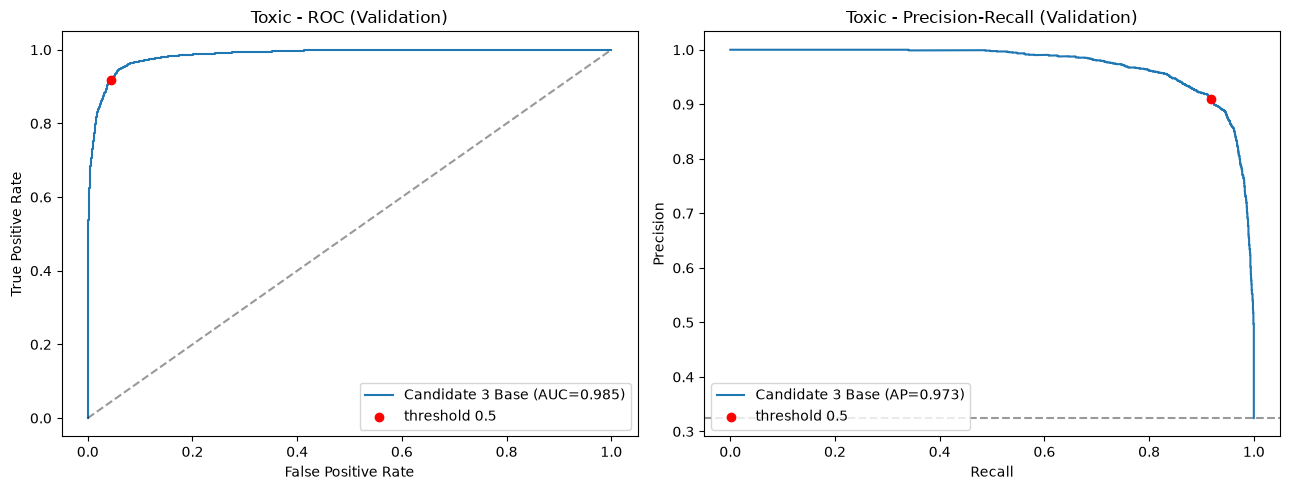

In [28]:
from sklearn.metrics import roc_curve, precision_recall_curve, average_precision_score

y_val = jigsaw_val["label"].values

fpr, tpr, roc_thr = roc_curve(y_val, toxic_cnd_base_prob)
prec, rec, pr_thr = precision_recall_curve(y_val, toxic_cnd_base_prob)

# Where the default 0.5 threshold sits on the curves
pred_05 = toxic_cnd_base_prob >= 0.5
fpr_05 = (pred_05 & (y_val == 0)).sum() / (y_val == 0).sum()
tpr_05 = (pred_05 & (y_val == 1)).sum() / (y_val == 1).sum()
prec_05 = (pred_05 & (y_val == 1)).sum() / max(pred_05.sum(), 1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

ax1.plot(fpr, tpr, label=f"Candidate 3 Base (AUC={roc_auc_score(y_val, toxic_cnd_base_prob):.3f})")
ax1.plot([0, 1], [0, 1], "k--", alpha=0.4)
ax1.scatter([fpr_05], [tpr_05], color="red", zorder=3, label="threshold 0.5")
ax1.set(xlabel="False Positive Rate", ylabel="True Positive Rate", title="Toxic - ROC (Validation)")
ax1.legend(loc="lower right")

ax2.plot(rec, prec, label=f"Candidate 3 Base (AP={average_precision_score(y_val, toxic_cnd_base_prob):.3f})")
ax2.axhline(y_val.mean(), color="k", ls="--", alpha=0.4)
ax2.scatter([tpr_05], [prec_05], color="red", zorder=3, label="threshold 0.5")
ax2.set(xlabel="Recall", ylabel="Precision", title="Toxic - Precision-Recall (Validation)")
ax2.legend(loc="lower left")

plt.tight_layout()
plt.show()

## Threshold Selection (Validation)

In [36]:
def threshold_at_fpr(y_true, probs, max_fpr):
    # Highest recall while the false positive rate stays at or below max_fpr
    fpr, tpr, thr = roc_curve(y_true, probs)
    i = np.where(fpr <= max_fpr)[0][-1]
    return thr[i]


def threshold_summary(y_true, probs, thresholds):
    rows = []
    for name, t in thresholds.items():
        pred = probs >= t
        rows.append({
            "rule": name,
            "threshold": t,
            "recall (TPR)": (pred & (y_true == 1)).sum() / (y_true == 1).sum(),
            "false positive rate": (pred & (y_true == 0)).sum() / (y_true == 0).sum(),
            "precision": (pred & (y_true == 1)).sum() / max(pred.sum(), 1),
            "flagged %": pred.mean() * 100
        })
    return pd.DataFrame(rows)


# Best-F1 point from the precision-recall curve
f1_curve = 2 * prec[:-1] * rec[:-1] / np.maximum(prec[:-1] + rec[:-1], 1e-12)

candidate_thresholds = {
    "default 0.5": 0.5,
    "max recall, FPR <= 1%": threshold_at_fpr(y_val, toxic_cnd_base_prob, 0.01),
    "max recall, FPR <= 2%": threshold_at_fpr(y_val, toxic_cnd_base_prob, 0.02),
    "max recall, FPR <= 3%": threshold_at_fpr(y_val, toxic_cnd_base_prob, 0.03),
    "max recall, FPR <= 4%": threshold_at_fpr(y_val, toxic_cnd_base_prob, 0.04),
    "max recall, FPR <= 5%": threshold_at_fpr(y_val, toxic_cnd_base_prob, 0.05),
    "max recall, FPR <= 10%": threshold_at_fpr(y_val, toxic_cnd_base_prob, 0.10),
    "best F1": pr_thr[np.argmax(f1_curve)]
}

display(threshold_summary(y_val, toxic_cnd_base_prob, candidate_thresholds))

# Pick the rule that fits the product, then use that value below
toxic_threshold = candidate_thresholds["max recall, FPR <= 3%"]
print("Chosen toxic threshold:", toxic_threshold)

,rule,threshold,recall (TPR),false positive rate,precision,flagged %
0,default 0.5,0.500000,0.917831,0.043624,0.909980,32.733333
1,"max recall, FPR <= 1%",0.835357,0.746919,0.009870,0.973233,24.906667
2,"max recall, FPR <= 2%",0.713054,0.838127,0.019937,0.952826,28.546667
3,"max recall, FPR <= 3%",0.619451,0.873048,0.029807,0.933656,30.346667
4,"max recall, FPR <= 4%",0.528974,0.912079,0.039479,0.917355,32.266667
5,"max recall, FPR <= 5%",0.453831,0.925226,0.049941,0.899002,33.400000
6,"max recall, FPR <= 10%",0.253683,0.968365,0.097710,0.826438,38.026667
7,best F1,0.399037,0.945768,0.058034,0.886749,34.613333


Chosen toxic threshold: 0.6194506823036253


## Candidate Ensemble Test Result at Chosen Threshold

In [37]:
toxic_cnd_base_tuned_test_results = evaluate_binary(
    toxic_test_combined["label"].values,
    toxic_cnd_base_test_prob,
    threshold=toxic_threshold,
    model_name=("Toxic Candidate Ensemble (3 Base Models) (Test, tuned threshold)")
)


Toxic Candidate Ensemble (3 Base Models) (Test, tuned threshold)
{'model': 'Toxic Candidate Ensemble (3 Base Models) (Test, tuned threshold)', 'accuracy': 0.8818302911427609, 'precision': 0.5326594090202177, 'recall': 0.905186653452263, 'f1': 0.6706645453432872, 'roc_auc': 0.9567706935477626}
              precision    recall  f1-score   support

           0       0.98      0.88      0.93     59236
           1       0.53      0.91      0.67      9081

    accuracy                           0.88     68317
   macro avg       0.76      0.89      0.80     68317
weighted avg       0.92      0.88      0.89     68317

Confusion matrix:
 [[52024  7212]
 [  861  8220]]
